# plutovizu — Analyse qualitative

API chaînable : chaque méthode retourne le graphique, on enchaîne les appels et on termine par `.show()`. Le thème **editorial** est appliqué dès l'import. Fiches détaillées (données attendues, paramètres) dans la [documentation](https://mr-kam.github.io/plutovizu/).

In [1]:
import tempfile
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from plutovizu import (Chart, cm, get_fonts, list_themes, set_theme, texture_class,
                       theme_context)

# Taille par défaut d'un graphique : 16 × 10 cm ; cm(largeur, hauteur) pour une autre taille.
# Export (save) : 400 dpi par défaut.

## Analyse qualitative

Réponses ouvertes, entretiens et questionnaires d'opinion.

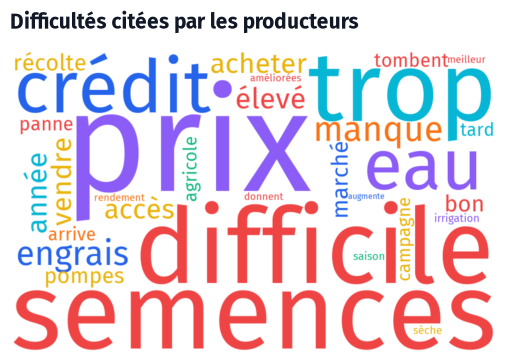

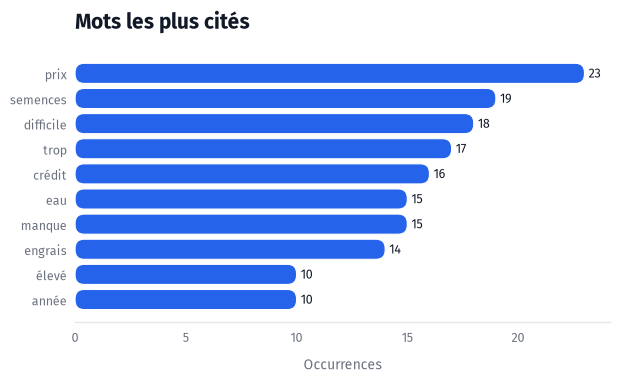

In [2]:
temoignages = [
    "Le prix de l'engrais est trop élevé cette année",
    "Manque d'eau pour l'irrigation en saison sèche",
    "Accès au crédit difficile pour acheter les semences",
    "Les semences améliorées donnent un meilleur rendement",
    "Le prix des semences et de l'engrais augmente encore",
    "L'eau manque et les pompes tombent souvent en panne",
    "Le crédit agricole arrive trop tard pour la campagne",
    "Difficile de vendre la récolte à bon prix au marché",
]
rng = np.random.default_rng(5)
enquete = pd.DataFrame({'reponse': rng.choice(temoignages, 60)})

(Chart(enquete)
    .word_cloud('reponse')
    .title('Difficultés citées par les producteurs')
    .show())

(Chart(enquete)
    .word_frequency('reponse', top=10)
    .title('Mots les plus cités')
    .tight_layout()
    .show())

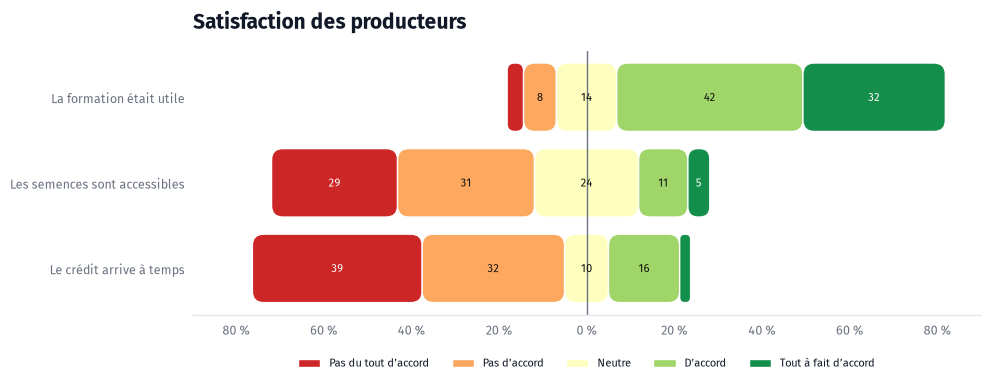

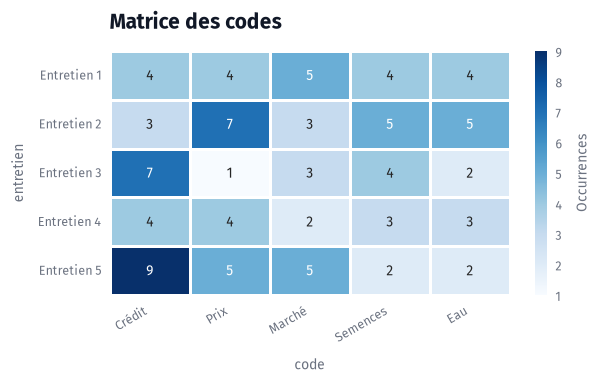

In [3]:
echelle = ['Pas du tout d’accord', 'Pas d’accord', 'Neutre', 'D’accord', 'Tout à fait d’accord']
opinions = pd.DataFrame({q: rng.choice(echelle, 80, p=p) for q, p in {
    'La formation était utile': [.05, .10, .15, .40, .30],
    'Les semences sont accessibles': [.25, .30, .20, .15, .10],
    'Le crédit arrive à temps': [.35, .30, .15, .15, .05],
}.items()})

(Chart(opinions, figsize=(10, 4))
    .likert(list(opinions.columns), order=echelle)
    .title('Satisfaction des producteurs')
    .tight_layout()
    .show())

segments = pd.DataFrame({
    'entretien': rng.choice([f'Entretien {i}' for i in range(1, 6)], 100),
    'code': rng.choice(['Eau', 'Prix', 'Crédit', 'Semences', 'Marché'], 100),
})
(Chart(segments)
    .code_matrix('entretien', 'code')
    .title('Matrice des codes')
    .tight_layout()
    .show())